In [1]:

from pathlib import Path
import random
import numpy as np
import torch
import torch.nn as nn
from torchvision import models

# =====================================================
# 1. REPRODUCIBILITY
# =====================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# =====================================================
# 2. PROJECT PATHS
# =====================================================

DATA_DIR = Path.cwd()

SPLIT_FILE = DATA_DIR / "dataset_split.csv"

BASELINE_CHECKPOINT = (
    DATA_DIR
    / "results"
    / "resnet50"
    / "checkpoints"
    / "resnet50_best.pth"
)

RESULTS_DIR = (
    DATA_DIR / "results" / "resnet50_finetune"
)

CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
PLOTS_DIR = RESULTS_DIR / "plots"

# =====================================================
# 3. DEVICE
# =====================================================

DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

assert SPLIT_FILE.exists()
assert BASELINE_CHECKPOINT.exists()

# =====================================================
# 4. LOAD HEAD-ONLY CHECKPOINT
# =====================================================

checkpoint = torch.load(
    BASELINE_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["model_name"] == "resnet50"
assert checkpoint["epoch"] == 10

baseline_f1 = float(
    checkpoint["val_macro_f1"]
)

# =====================================================
# 5. RECREATE RESNET-50 ARCHITECTURE
# =====================================================

model = models.resnet50(weights=None)

model.fc = nn.Linear(
    model.fc.in_features,
    3
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

# =====================================================
# 6. FREEZE ALL PARAMETERS
# =====================================================

for param in model.parameters():
    param.requires_grad = False

# =====================================================
# 7. UNFREEZE FINAL RESIDUAL BLOCK
# =====================================================

for param in model.layer4[-1].parameters():
    param.requires_grad = True

# Unfreeze three-class classification head
for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(DEVICE)

# Keep BatchNorm running statistics frozen
model.eval()

# =====================================================
# 8. VERIFY PARAMETER COUNTS
# =====================================================

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

head_params = sum(
    p.numel() for p in model.fc.parameters()
)

block_params = sum(
    p.numel() for p in model.layer4[-1].parameters()
)

assert head_params == 6147
assert total_params == 23_514_179
assert trainable_params == block_params + head_params

# =====================================================
# 9. SUMMARY
# =====================================================

print("RESNET-50 FINE-TUNING SETUP VERIFIED")
print("=" * 60)

print("Architecture: ResNet-50")
print("Device:", DEVICE)

print("\nBASELINE")
print("Checkpoint epoch:", checkpoint["epoch"])
print(f"Baseline macro-F1: {baseline_f1:.4f}")
print(f"Baseline accuracy: {checkpoint['val_accuracy']:.4%}")

print("\nTRAINABLE COMPONENTS")
print("Final residual block: layer4[-1]")
print("Classifier: fc")

print("\nPARAMETER COUNTS")
print(f"Total: {total_params:,}")
print(f"Trainable: {trainable_params:,}")
print(f"Frozen: {frozen_params:,}")
print(f"Final block: {block_params:,}")
print(f"Classifier: {head_params:,}")
print(f"Trainable fraction: {100 * trainable_params / total_params:.2f}%")

print("\nPretrained features restored: YES")
print("Ready for fine-tuning configuration")


RESNET-50 FINE-TUNING SETUP VERIFIED
Architecture: ResNet-50
Device: mps

BASELINE
Checkpoint epoch: 10
Baseline macro-F1: 0.9537
Baseline accuracy: 97.8571%

TRAINABLE COMPONENTS
Final residual block: layer4[-1]
Classifier: fc

PARAMETER COUNTS
Total: 23,514,179
Trainable: 4,468,739
Frozen: 19,045,440
Final block: 4,462,592
Classifier: 6,147
Trainable fraction: 19.00%

Pretrained features restored: YES
Ready for fine-tuning configuration


In [2]:

import csv
from collections import Counter

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# =====================================================
# 1. CLASS MAPPING
# =====================================================

CLASSES = ["Brittle", "Ductile", "Mixed"]

class_to_idx = {
    "Brittle": 0,
    "Ductile": 1,
    "Mixed": 2
}

assert checkpoint["class_to_idx"] == class_to_idx

# =====================================================
# 2. LOAD ORIGINAL DATASET SPLIT
# =====================================================

with open(SPLIT_FILE, "r", encoding="utf-8-sig") as f:
    split_records = list(csv.DictReader(f))

train_records = [
    r for r in split_records
    if r["split"] == "train"
]

val_records = [
    r for r in split_records
    if r["split"] == "validation"
]

test_records = [
    r for r in split_records
    if r["split"] == "test"
]

assert len(train_records) == 1402
assert len(val_records) == 280
assert len(test_records) == 279

# =====================================================
# 3. IMAGE PREPROCESSING
# =====================================================

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# =====================================================
# 4. DATASET CLASS
# =====================================================

class SEMDataset(Dataset):

    def __init__(self, records, data_dir, transform):
        self.records = records
        self.data_dir = Path(data_dir)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):

        record = self.records[idx]

        image_path = (
            self.data_dir
            / record["label"]
            / record["filename"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        label = class_to_idx[record["label"]]

        return image, label

# =====================================================
# 5. DATALOADERS
# =====================================================

train_dataset = SEMDataset(
    train_records, DATA_DIR, train_transform
)

val_dataset = SEMDataset(
    val_records, DATA_DIR, eval_transform
)

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# =====================================================
# 6. CLASS-WEIGHTED LOSS
# =====================================================

train_counts = Counter(
    r["label"] for r in train_records
)

class_weights = torch.tensor(
    [
        len(train_records) /
        (len(CLASSES) * train_counts[c])
        for c in CLASSES
    ],
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# =====================================================
# 7. DIFFERENTIAL LEARNING RATES
# =====================================================

BLOCK_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.layer4[-1].parameters(),
            "lr": BLOCK_LR
        },
        {
            "params": model.fc.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

# =====================================================
# 8. VERIFY OPTIMIZER PARAMETERS
# =====================================================

optimized_params = sum(
    p.numel()
    for group in optimizer.param_groups
    for p in group["params"]
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

assert optimized_params == trainable_params
assert trainable_params == 4_468_739

# =====================================================
# 9. DIAGNOSTIC GRADIENT CHECK
# =====================================================

# Keep frozen BatchNorm running statistics unchanged
model.eval()

optimizer.zero_grad(set_to_none=True)

images, labels = next(iter(train_loader))

outputs = model(images.to(DEVICE))

loss = criterion(
    outputs,
    labels.to(DEVICE)
)

loss.backward()

# Verify gradients in final residual block
block_grads = [
    p.grad
    for p in model.layer4[-1].parameters()
    if p.requires_grad
]

assert all(g is not None for g in block_grads)
assert all(torch.isfinite(g).all() for g in block_grads)
assert any(g.abs().sum().item() > 0 for g in block_grads)

# Verify gradients in classifier
assert model.fc.weight.grad is not None
assert model.fc.bias.grad is not None

assert torch.isfinite(model.fc.weight.grad).all()
assert model.fc.weight.grad.abs().sum().item() > 0

# Frozen backbone must have no gradients
frozen_grads = [
    name
    for name, p in model.named_parameters()
    if not p.requires_grad and p.grad is not None
]

assert len(frozen_grads) == 0

# Diagnostic only: do not update model weights
optimizer.zero_grad(set_to_none=True)

# =====================================================
# 10. SUMMARY
# =====================================================

print("RESNET-50 FINE-TUNING CONFIGURATION VERIFIED")
print("=" * 60)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("\nCLASS WEIGHTS")
for c, w in zip(CLASSES, class_weights.tolist()):
    print(f"{c}: {w:.4f}")

print("\nOPTIMIZER")
print("Optimizer: AdamW")
print("Final block LR:", BLOCK_LR)
print("Classifier LR:", HEAD_LR)
print("Weight decay:", WEIGHT_DECAY)

print("\nGRADIENT CHECK")
print(f"Diagnostic loss: {loss.item():.4f}")
print("Final residual block gradients: PASSED")
print("Classification head gradients: PASSED")
print("Frozen backbone gradients: NONE")

print("\nPARAMETERS")
print(f"Optimized: {optimized_params:,}")
print(f"Trainable: {trainable_params:,}")

print("\nReady for selective fine-tuning")


RESNET-50 FINE-TUNING CONFIGURATION VERIFIED
Training images: 1402
Validation images: 280
Training batches: 88
Validation batches: 18

CLASS WEIGHTS
Brittle: 0.7934
Ductile: 0.6573
Mixed: 4.5817

OPTIMIZER
Optimizer: AdamW
Final block LR: 1e-05
Classifier LR: 0.0001
Weight decay: 0.0001

GRADIENT CHECK
Diagnostic loss: 0.1244
Final residual block gradients: PASSED
Classification head gradients: PASSED
Frozen backbone gradients: NONE

PARAMETERS
Optimized: 4,468,739
Trainable: 4,468,739

Ready for selective fine-tuning


In [3]:

import random
import time
import json
import numpy as np
import torch
import torch.nn as nn

from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

# =====================================================
# 1. FINE-TUNING CONFIGURATION
# =====================================================

RUN_SEED = 42
MAX_EPOCHS = 30
PATIENCE = 4

BLOCK_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 1e-4
GRAD_CLIP_NORM = 1.0

random.seed(RUN_SEED)
np.random.seed(RUN_SEED)
torch.manual_seed(RUN_SEED)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = (
    CHECKPOINT_DIR / "resnet50_finetuned_best.pth"
)

if checkpoint_path.exists():
    raise FileExistsError(
        f"Checkpoint already exists: {checkpoint_path}"
    )

# =====================================================
# 2. RELOAD ORIGINAL HEAD-ONLY CHECKPOINT
# =====================================================

baseline_checkpoint = torch.load(
    BASELINE_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

assert baseline_checkpoint["model_name"] == "resnet50"
assert baseline_checkpoint["class_to_idx"] == class_to_idx

baseline_f1 = float(
    baseline_checkpoint["val_macro_f1"]
)

model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 3)

model.load_state_dict(
    baseline_checkpoint["model_state_dict"]
)

for p in model.parameters():
    p.requires_grad = False

for p in model.layer4[-1].parameters():
    p.requires_grad = True

for p in model.fc.parameters():
    p.requires_grad = True

model = model.to(DEVICE)
model.eval()

# =====================================================
# 3. FRESH OPTIMIZER
# =====================================================

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.layer4[-1].parameters(),
            "lr": BLOCK_LR
        },
        {
            "params": model.fc.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

assert sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
) == 4_468_739

# =====================================================
# 4. HISTORY AND EARLY STOPPING
# =====================================================

history_ft = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "val_mixed_f1": [],
    "val_mixed_recall": [],
    "epoch_time": []
}

best_f1 = baseline_f1
best_epoch = 0

has_new_best = False
epochs_without_improvement = 0

# =====================================================
# 5. CHECKPOINT HELPER
# =====================================================

def save_checkpoint(epoch, macro_f1, accuracy):

    torch.save(
        {
            "model_state_dict": {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            },
            "epoch": epoch,
            "val_macro_f1": float(macro_f1),
            "val_accuracy": float(accuracy),
            "model_name": "resnet50",
            "class_to_idx": class_to_idx,
            "experiment": "final_block_finetuning",
            "run_seed": RUN_SEED,
            "baseline_checkpoint": str(BASELINE_CHECKPOINT)
        },
        checkpoint_path
    )

# Preserve head-only model as fallback
save_checkpoint(
    epoch=0,
    macro_f1=baseline_f1,
    accuracy=baseline_checkpoint["val_accuracy"]
)

print("STARTING RESNET-50 FINE-TUNING")
print("=" * 80)
print("Starting checkpoint epoch:", baseline_checkpoint["epoch"])
print(f"Baseline Macro-F1: {baseline_f1:.4f}")
print("Run seed:", RUN_SEED)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Gradient clipping:", GRAD_CLIP_NORM)
print()

# =====================================================
# 6. TRAINING LOOP
# =====================================================

total_start = time.perf_counter()

for epoch in range(MAX_EPOCHS):

    if DEVICE.type == "mps":
        torch.mps.synchronize()

    start_time = time.perf_counter()

    # Keep BatchNorm running statistics fixed
    model.eval()

    train_loss_total = 0.0
    train_samples = 0

    # -----------------------------
    # TRAINING
    # -----------------------------

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            (
                p for p in model.parameters()
                if p.requires_grad
            ),
            max_norm=GRAD_CLIP_NORM
        )

        optimizer.step()

        train_loss_total += (
            loss.item() * labels.size(0)
        )
        train_samples += labels.size(0)

    train_loss = train_loss_total / train_samples

    # -----------------------------
    # VALIDATION
    # -----------------------------

    model.eval()

    val_loss_total = 0.0
    val_samples = 0

    all_labels = []
    all_predictions = []

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += (
                loss.item() * labels.size(0)
            )
            val_samples += labels.size(0)

            predictions = outputs.argmax(dim=1)

            all_labels.extend(
                labels.cpu().tolist()
            )
            all_predictions.extend(
                predictions.cpu().tolist()
            )

    val_loss = val_loss_total / val_samples

    # -----------------------------
    # METRICS
    # -----------------------------

    val_accuracy = accuracy_score(
        all_labels, all_predictions
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    val_mixed_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    val_mixed_recall = recall_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    if DEVICE.type == "mps":
        torch.mps.synchronize()

    elapsed = time.perf_counter() - start_time

    # -----------------------------
    # RECORD HISTORY
    # -----------------------------

    history_ft["train_loss"].append(train_loss)
    history_ft["val_loss"].append(val_loss)
    history_ft["val_accuracy"].append(val_accuracy)
    history_ft["val_macro_f1"].append(val_macro_f1)
    history_ft["val_mixed_f1"].append(val_mixed_f1)
    history_ft["val_mixed_recall"].append(val_mixed_recall)
    history_ft["epoch_time"].append(elapsed)

    # -----------------------------
    # CHECKPOINT AND EARLY STOPPING
    # -----------------------------

    if val_macro_f1 > best_f1 + 1e-6:

        best_f1 = val_macro_f1
        best_epoch = epoch + 1

        save_checkpoint(
            epoch=best_epoch,
            macro_f1=best_f1,
            accuracy=val_accuracy
        )

        has_new_best = True
        epochs_without_improvement = 0

        status = "NEW BEST"

    elif not has_new_best:

        status = "Searching for first improvement"

    else:

        epochs_without_improvement += 1

        status = (
            f"No improvement "
            f"({epochs_without_improvement}/{PATIENCE})"
        )

    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.4f} | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"Mixed F1: {val_mixed_f1:.4f} | "
        f"Mixed Recall: {val_mixed_recall:.4f} | "
        f"Time: {elapsed:.1f}s | "
        f"{status}",
        flush=True
    )

    if (
        has_new_best
        and epochs_without_improvement >= PATIENCE
    ):
        print(
            "\nEarly stopping: 4 epochs without "
            "improvement after first new best."
        )
        break

# =====================================================
# 7. RESTORE BEST CHECKPOINT
# =====================================================

if DEVICE.type == "mps":
    torch.mps.synchronize()

total_finetune_time = time.perf_counter() - total_start

best_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# Save complete training history separately
with open(
    RESULTS_DIR / "finetuning_history.json",
    "w"
) as f:
    json.dump(history_ft, f, indent=2)

# =====================================================
# 8. FINAL SUMMARY
# =====================================================

print("\nRESNET-50 FINE-TUNING COMPLETED")
print("=" * 65)

print("First improvement achieved:", has_new_best)
print("Best fine-tuning epoch:", best_epoch)
print(f"Baseline Macro-F1: {baseline_f1:.4f}")
print(f"Best Macro-F1:     {best_f1:.4f}")
print(f"Improvement:      {best_f1 - baseline_f1:+.4f}")

print("Total epochs:", len(history_ft["train_loss"]))
print(f"Average epoch time: {np.mean(history_ft['epoch_time']):.1f}s")
print(f"Total fine-tuning time: {total_finetune_time:.1f}s")

print("\nCheckpoint:", checkpoint_path)
print("Best checkpoint restored: YES")


STARTING RESNET-50 FINE-TUNING
Starting checkpoint epoch: 10
Baseline Macro-F1: 0.9537
Run seed: 42
Maximum epochs: 30
Early stopping patience: 4
Gradient clipping: 1.0

Epoch 01/30 | Train Loss: 0.1244 | Val Loss: 0.0619 | Accuracy: 0.9857 | Macro-F1: 0.9701 | Mixed F1: 0.9302 | Mixed Recall: 0.9524 | Time: 13.8s | NEW BEST
Epoch 02/30 | Train Loss: 0.0995 | Val Loss: 0.0640 | Accuracy: 0.9714 | Macro-F1: 0.9287 | Mixed F1: 0.8205 | Mixed Recall: 0.7619 | Time: 13.4s | No improvement (1/4)
Epoch 03/30 | Train Loss: 0.1377 | Val Loss: 0.0578 | Accuracy: 0.9857 | Macro-F1: 0.9701 | Mixed F1: 0.9302 | Mixed Recall: 0.9524 | Time: 13.4s | No improvement (2/4)
Epoch 04/30 | Train Loss: 0.1120 | Val Loss: 0.0486 | Accuracy: 0.9821 | Macro-F1: 0.9602 | Mixed F1: 0.9048 | Mixed Recall: 0.9048 | Time: 13.7s | No improvement (3/4)
Epoch 05/30 | Train Loss: 0.1091 | Val Loss: 0.0508 | Accuracy: 0.9821 | Macro-F1: 0.9602 | Mixed F1: 0.9048 | Mixed Recall: 0.9048 | Time: 13.7s | No improvement (4/


RESNET-50 HEAD ONLY
              precision    recall  f1-score   support

     Brittle     0.9913    0.9744    0.9828       117
     Ductile     0.9929    0.9859    0.9894       142
       Mixed     0.8333    0.9524    0.8889        21

    accuracy                         0.9786       280
   macro avg     0.9392    0.9709    0.9537       280
weighted avg     0.9803    0.9786    0.9791       280


RESNET-50 FINE-TUNED
              precision    recall  f1-score   support

     Brittle     0.9914    0.9829    0.9871       117
     Ductile     0.9930    0.9930    0.9930       142
       Mixed     0.9091    0.9524    0.9302        21

    accuracy                         0.9857       280
   macro avg     0.9645    0.9761    0.9701       280
weighted avg     0.9860    0.9857    0.9858       280


PREDICTION CHANGES
Head-only errors: 6
Fine-tuned errors: 4
Corrected: 2
New errors: 0

CHANGED PREDICTIONS
         filename      group  actual head_prediction finetuned_prediction    status
  

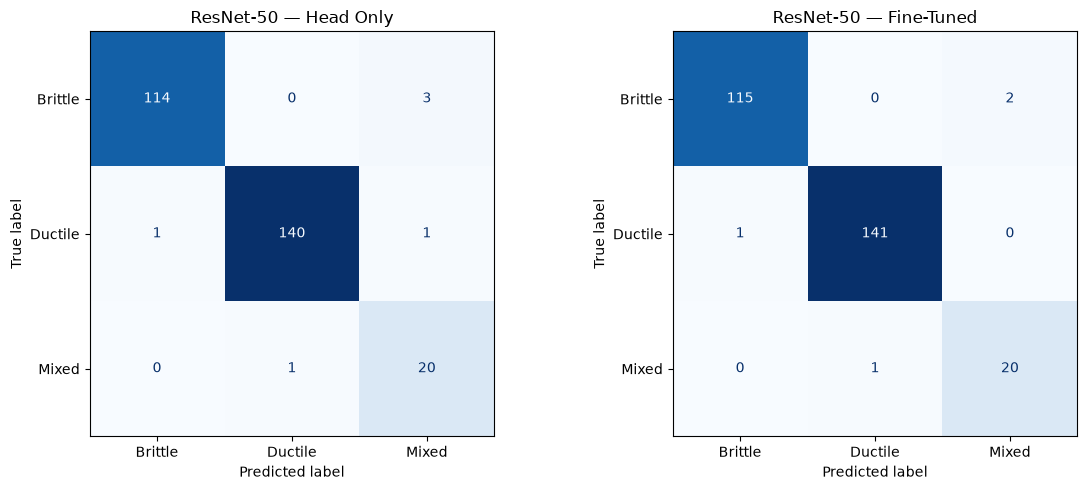


VALIDATION ANALYSIS COMPLETE
Head-only Macro-F1: 0.9537
Fine-tuned Macro-F1: 0.9701
Improvement: +0.0164
Metrics, predictions and plot saved.


In [4]:

import json
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# =====================================================
# 1. LOAD BOTH CHECKPOINTS
# =====================================================

head_checkpoint = torch.load(
    BASELINE_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

fine_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

def build_resnet50(state_dict):
    net = models.resnet50(weights=None)
    net.fc = nn.Linear(net.fc.in_features, 3)
    net.load_state_dict(state_dict)
    return net.to(DEVICE).eval()

head_model = build_resnet50(
    head_checkpoint["model_state_dict"]
)

fine_model = build_resnet50(
    fine_checkpoint["model_state_dict"]
)

# =====================================================
# 2. EVALUATION HELPER
# =====================================================

def evaluate_model(net, loader):
    actual = []
    predicted = []

    net.eval()

    with torch.inference_mode():
        for images, labels in loader:

            outputs = net(images.to(DEVICE))
            preds = outputs.argmax(dim=1)

            actual.extend(labels.tolist())
            predicted.extend(preds.cpu().tolist())

    return actual, predicted

# =====================================================
# 3. EVALUATE BOTH MODELS
# =====================================================

y_true, head_preds = evaluate_model(
    head_model, val_loader
)

y_true_ft, fine_preds = evaluate_model(
    fine_model, val_loader
)

assert y_true == y_true_ft

assert y_true == [
    class_to_idx[r["label"]]
    for r in val_records
]

assert len(y_true) == 280

head_f1 = f1_score(
    y_true, head_preds,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

fine_f1 = f1_score(
    y_true, fine_preds,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

assert abs(
    head_f1 - head_checkpoint["val_macro_f1"]
) < 1e-5

assert abs(
    fine_f1 - fine_checkpoint["val_macro_f1"]
) < 1e-5

# =====================================================
# 4. CLASSIFICATION REPORTS
# =====================================================

for name, preds in [
    ("HEAD ONLY", head_preds),
    ("FINE-TUNED", fine_preds)
]:
    print("\nRESNET-50", name)
    print("=" * 60)

    print(classification_report(
        y_true,
        preds,
        labels=[0, 1, 2],
        target_names=CLASSES,
        digits=4,
        zero_division=0
    ))

# =====================================================
# 5. COMPARE PREDICTIONS
# =====================================================

audit_rows = []

for record, actual, before, after in zip(
    val_records, y_true, head_preds, fine_preds
):
    if before != actual and after == actual:
        status = "Corrected"
    elif before == actual and after != actual:
        status = "New error"
    elif before != actual and after != actual:
        status = "Still incorrect"
    else:
        status = "Still correct"

    audit_rows.append({
        "filename": record["filename"],
        "group": record["group"],
        "actual": CLASSES[actual],
        "head_prediction": CLASSES[before],
        "finetuned_prediction": CLASSES[after],
        "status": status
    })

audit = pd.DataFrame(audit_rows)

changed = audit[
    audit["head_prediction"] !=
    audit["finetuned_prediction"]
].copy()

print("\nPREDICTION CHANGES")
print("=" * 60)

print("Head-only errors:",
      sum(a != p for a, p in zip(y_true, head_preds)))

print("Fine-tuned errors:",
      sum(a != p for a, p in zip(y_true, fine_preds)))

print("Corrected:",
      (audit["status"] == "Corrected").sum())

print("New errors:",
      (audit["status"] == "New error").sum())

print("\nCHANGED PREDICTIONS")
print(changed.to_string(index=False))

print("\nREMAINING ERRORS")
print(
    audit[
        audit["finetuned_prediction"] != audit["actual"]
    ].to_string(index=False)
)

# =====================================================
# 6. CONFUSION MATRIX COMPARISON
# =====================================================

head_cm = confusion_matrix(
    y_true, head_preds, labels=[0, 1, 2]
)

fine_cm = confusion_matrix(
    y_true, fine_preds, labels=[0, 1, 2]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, cm, title in [
    (axes[0], head_cm, "Head Only"),
    (axes[1], fine_cm, "Fine-Tuned")
]:
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASSES
    )
    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )
    ax.set_title(f"ResNet-50 — {title}")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "resnet50_finetuning_comparison.png",
    dpi=200
)

plt.show()

# =====================================================
# 7. SAVE RESULTS
# =====================================================

audit.to_csv(
    RESULTS_DIR / "validation_predictions.csv",
    index=False
)

validation_results = {}

for name, preds in [
    ("head_only", head_preds),
    ("fine_tuned", fine_preds)
]:
    validation_results[name] = {
        "accuracy": float(
            accuracy_score(y_true, preds)
        ),
        "macro_f1": float(
            f1_score(
                y_true, preds,
                labels=[0, 1, 2],
                average="macro",
                zero_division=0
            )
        ),
        "confusion_matrix": confusion_matrix(
            y_true, preds,
            labels=[0, 1, 2]
        ).tolist(),
        "classification_report": classification_report(
            y_true, preds,
            labels=[0, 1, 2],
            target_names=CLASSES,
            output_dict=True,
            zero_division=0
        )
    }

with open(
    RESULTS_DIR / "validation_metrics.json",
    "w"
) as f:
    json.dump(validation_results, f, indent=2)

print("\nVALIDATION ANALYSIS COMPLETE")
print("=" * 60)
print(f"Head-only Macro-F1: {head_f1:.4f}")
print(f"Fine-tuned Macro-F1: {fine_f1:.4f}")
print(f"Improvement: {fine_f1 - head_f1:+.4f}")
print("Metrics, predictions and plot saved.")


RESNET-50 — HELD-OUT TEST RESULTS
Accuracy: 96.0573%
Macro-F1: 0.9007
Correct: 268/279
Errors: 11

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Brittle     0.9828    0.9828    0.9828       116
     Ductile     0.9857    0.9650    0.9753       143
       Mixed     0.6957    0.8000    0.7442        20

    accuracy                         0.9606       279
   macro avg     0.8880    0.9159    0.9007       279
weighted avg     0.9637    0.9606    0.9618       279


CONFUSION MATRIX
[[114   0   2]
 [  0 138   5]
 [  2   2  16]]

MISCLASSIFIED TEST IMAGES
           filename        group  actual predicted
100Cr6_AR_33_19.png 100Cr6_AR_33 Brittle     Mixed
100Cr6_AR_33_27.png 100Cr6_AR_33 Brittle     Mixed
100Cr6_AR_44_14.png 100Cr6_AR_44 Ductile     Mixed
   304_H2_05_26.png    304_H2_05 Ductile     Mixed
   304_H2_05_27.png    304_H2_05 Ductile     Mixed
   304_H2_05_30.png    304_H2_05 Ductile     Mixed
   316L_AR_16_4.png   316L_AR_16 Ductile     Mixed

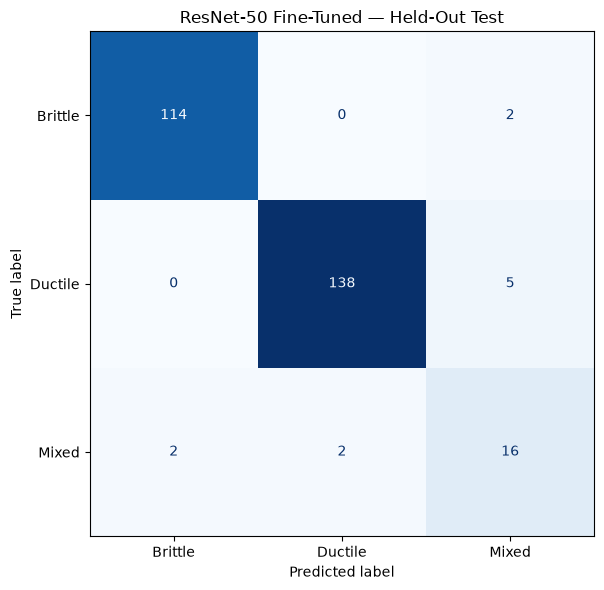


TEST EVALUATION COMPLETE
Results saved to: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/resnet50_finetune
Test predictions: test_predictions.csv
Metrics: test_metrics.json
Confusion matrix: resnet50_test_confusion_matrix.png


In [5]:

import json
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# =====================================================
# 1. LOAD BEST FINE-TUNED CHECKPOINT
# =====================================================

final_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert final_checkpoint["model_name"] == "resnet50"
assert final_checkpoint["epoch"] == 1
assert final_checkpoint["class_to_idx"] == class_to_idx

model.load_state_dict(
    final_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# =====================================================
# 2. BUILD HELD-OUT TEST DATASET
# =====================================================

# Original test records only.
# No augmented images or training transforms.
test_dataset = SEMDataset(
    test_records,
    DATA_DIR,
    eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

assert len(test_dataset) == 279

# Verify group separation
train_groups = {r["group"] for r in train_records}
val_groups = {r["group"] for r in val_records}
test_groups = {r["group"] for r in test_records}

assert test_groups.isdisjoint(train_groups)
assert test_groups.isdisjoint(val_groups)

# =====================================================
# 3. TEST PREDICTIONS
# =====================================================

test_true = []
test_pred = []

with torch.inference_mode():

    for images, labels in test_loader:

        outputs = model(images.to(DEVICE))
        predictions = outputs.argmax(dim=1)

        test_true.extend(labels.tolist())
        test_pred.extend(predictions.cpu().tolist())

assert len(test_true) == 279
assert test_true == [
    class_to_idx[r["label"]]
    for r in test_records
]

# =====================================================
# 4. CALCULATE TEST METRICS
# =====================================================

test_accuracy = accuracy_score(
    test_true, test_pred
)

test_macro_f1 = f1_score(
    test_true,
    test_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

test_report = classification_report(
    test_true,
    test_pred,
    labels=[0, 1, 2],
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

test_cm = confusion_matrix(
    test_true,
    test_pred,
    labels=[0, 1, 2]
)

print("RESNET-50 — HELD-OUT TEST RESULTS")
print("=" * 65)

print(f"Accuracy: {test_accuracy:.4%}")
print(f"Macro-F1: {test_macro_f1:.4f}")

correct = sum(
    a == b for a, b in zip(test_true, test_pred)
)

print(f"Correct: {correct}/279")
print(f"Errors: {279 - correct}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    test_true,
    test_pred,
    labels=[0, 1, 2],
    target_names=CLASSES,
    digits=4,
    zero_division=0
))

print("\nCONFUSION MATRIX")
print(test_cm)

# =====================================================
# 5. PREDICTION-LEVEL ERROR AUDIT
# =====================================================

audit_rows = []

for record, actual, predicted in zip(
    test_records, test_true, test_pred
):

    filename = record["filename"]
    parts = Path(filename).stem.split("_")

    audit_rows.append({
        "filename": filename,
        "group": record["group"],
        "material": parts[0],
        "environment": (
            parts[1] if len(parts) > 1 else "Unknown"
        ),
        "actual": CLASSES[actual],
        "predicted": CLASSES[predicted],
        "correct": actual == predicted
    })

audit = pd.DataFrame(audit_rows)

errors = audit[~audit["correct"]].copy()

print("\nMISCLASSIFIED TEST IMAGES")
print("=" * 65)

if errors.empty:
    print("No misclassifications")
else:
    print(
        errors[
            [
                "filename", "group",
                "actual", "predicted"
            ]
        ].to_string(index=False)
    )

# =====================================================
# 6. ACCURACY BY MATERIAL
# =====================================================

print("\nACCURACY BY MATERIAL")
print("=" * 65)

by_material = audit.groupby("material").agg(
    images=("correct", "size"),
    correct=("correct", "sum")
)

by_material["accuracy"] = (
    by_material["correct"] /
    by_material["images"]
).round(4)

print(by_material.to_string())

# =====================================================
# 7. ACCURACY BY ENVIRONMENT
# =====================================================

print("\nACCURACY BY ENVIRONMENT")
print("=" * 65)

by_environment = audit.groupby("environment").agg(
    images=("correct", "size"),
    correct=("correct", "sum")
)

by_environment["accuracy"] = (
    by_environment["correct"] /
    by_environment["images"]
).round(4)

print(by_environment.to_string())

# =====================================================
# 8. TEST CONFUSION MATRIX
# =====================================================

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=CLASSES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "ResNet-50 Fine-Tuned — Held-Out Test"
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "resnet50_test_confusion_matrix.png",
    dpi=200
)

plt.show()

# =====================================================
# 9. SAVE RESULTS
# =====================================================

audit.to_csv(
    RESULTS_DIR / "test_predictions.csv",
    index=False
)

test_results = {
    "model": "resnet50",
    "training": "fine_tuned",
    "checkpoint_epoch": final_checkpoint["epoch"],
    "split": "test",
    "test_images": len(test_true),
    "accuracy": float(test_accuracy),
    "macro_f1": float(test_macro_f1),
    "confusion_matrix": test_cm.tolist(),
    "classification_report": test_report
}

with open(
    RESULTS_DIR / "test_metrics.json",
    "w"
) as f:
    json.dump(test_results, f, indent=2)

print("\nTEST EVALUATION COMPLETE")
print("=" * 65)
print("Results saved to:", RESULTS_DIR)
print("Test predictions: test_predictions.csv")
print("Metrics: test_metrics.json")
print("Confusion matrix: resnet50_test_confusion_matrix.png")
